In [1]:
import numpy as np
import pandas as pd

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/boat_vs_noise_audio_products.csv")

## One-Sample t-Test

### Statistical Question

Is the mean sale price of the selected audio products significantly
different from ₹1,650?

The complete dataset has an actual population mean of approximately
₹1,639.13. We will take a random sample and use a one-sample t-test
to determine whether there is sufficient evidence that the population
mean differs from the hypothesized value of ₹1,650.

This is an educational validation setup because the complete dataset
is available and therefore the actual population mean is known.

### Test Selection

We have:

- One numerical variable: `sale_price`
- One sample
- One hypothesized population mean
- Unknown population standard deviation
- Sample standard deviation is used to estimate the population standard deviation

Therefore, a one-sample t-test is appropriate.

The test statistic is:

t = (x̄ − μ₀) / (s / √n)

where:

x̄ = sample mean
μ₀ = hypothesized population mean
s = sample standard deviation
n = sample size

Degrees of freedom:

df = n − 1

Step 3 — Create the Random Sample
We'll use n = 30.

In [3]:
sample_t = df['sale_price'].sample(n=30, random_state=42)

sample_mean_t = sample_t.mean()
sample_std_t = sample_t.std(ddof=1)
sample_n_t = sample_t.count()

sample_mean_t, sample_std_t, sample_n_t

(np.float64(1836.9666666666667), np.float64(1037.2087371247005), np.int64(30))

Step 4 — Check the Test Assumptions
### Assumption 1: Independence

The observations should be independent of one another.

Each product listing is treated as an individual observation, and the
random sample is selected without intentionally pairing or grouping
observations.

Therefore, independence is assumed for this analysis.

Note: Independence cannot be established purely from a statistical
plot; it primarily depends on how the data were collected.

### Assumption 2: Random Sampling

A random sample should be selected from the population.

We use random sampling with a fixed random seed for reproducibility.


In [5]:
df['sale_price'].dtype # Numerical variable 


dtype('int64')

### Assumption 3: Population Distribution

The population distribution of `sale_price` is inspected to identify
strong skewness and extreme values.

The distribution is right-skewed. Therefore, the normality assumption
should be considered carefully because the sample size is only 30.

However, the presence of skewness alone does not automatically
invalidate the t-test. We also inspect the sample for extreme
observations.

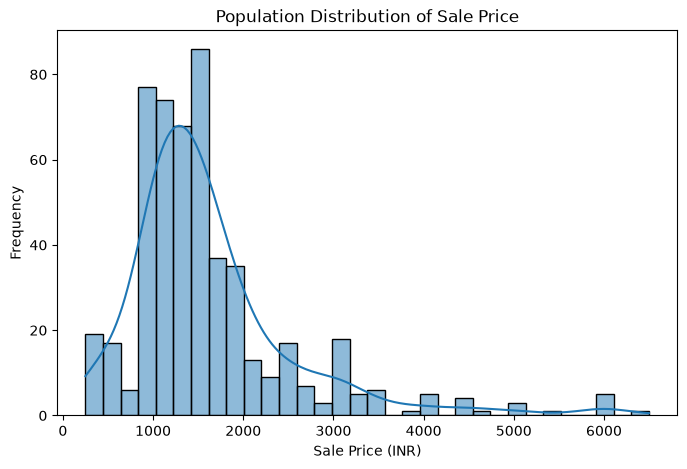

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(df['sale_price'].dropna(), kde=True)

plt.xlabel("Sale Price (INR)")
plt.ylabel("Frequency")
plt.title("Population Distribution of Sale Price")

plt.show()

### Sampling Distribution

The simulated sampling distribution of the sample mean is examined
to assess whether the sample mean has an approximately normal
sampling distribution.

Although the underlying sale-price population is right-skewed, the
sampling distribution of the mean is expected to become more
approximately normal as the sample size increases, according to the
Central Limit Theorem.

In [7]:
sample_means_t = []

for _ in range(5000):
    sample = df['sale_price'].sample(n=30)
    sample_means_t.append(sample.mean())

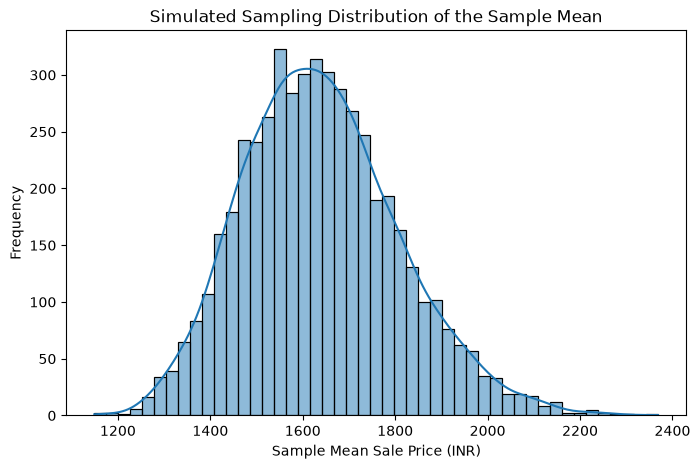

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(sample_means_t, kde=True)

plt.xlabel("Sample Mean Sale Price (INR)")
plt.ylabel("Frequency")
plt.title("Simulated Sampling Distribution of the Sample Mean")

plt.show()

Although the population distribution is right-skewed and the sample contains genuine extreme values, the simulated sampling distribution of the sample mean is approximately normal. Therefore, the one-sample t-test is reasonably appropriate

### Hypotheses

We want to determine whether the population mean sale price differs
from ₹1,650.

H₀: μ = ₹1,650

H₁: μ ≠ ₹1,650

This is a two-tailed one-sample t-test.

### Significance Level

α = 0.05

Since this is a two-tailed test, the total significance level of 0.05
is divided equally between the two tails:

α/2 = 0.025 per tail.

In [9]:
mu_0_t = 1650
alpha_t = 0.05

t_stat = (sample_mean_t - mu_0_t) / (
    sample_std_t / np.sqrt(sample_n_t)
)

t_stat

np.float64(0.9873216178140488)

In [10]:
df_t = sample_n_t - 1

df_t

np.int64(29)

In [11]:
p_value_t = 2 * stats.t.sf(abs(t_stat), df=df_t)

p_value_t

np.float64(0.3316515444709703)

In [12]:
t_critical = stats.t.ppf(1 - alpha_t / 2, df=df_t)

t_critical

np.float64(2.045229642132704)

In [13]:
if abs(t_stat) > t_critical:
    decision_t = "Reject H₀"
else:
    decision_t = "Fail to reject H₀"

decision_t

'Fail to reject H₀'

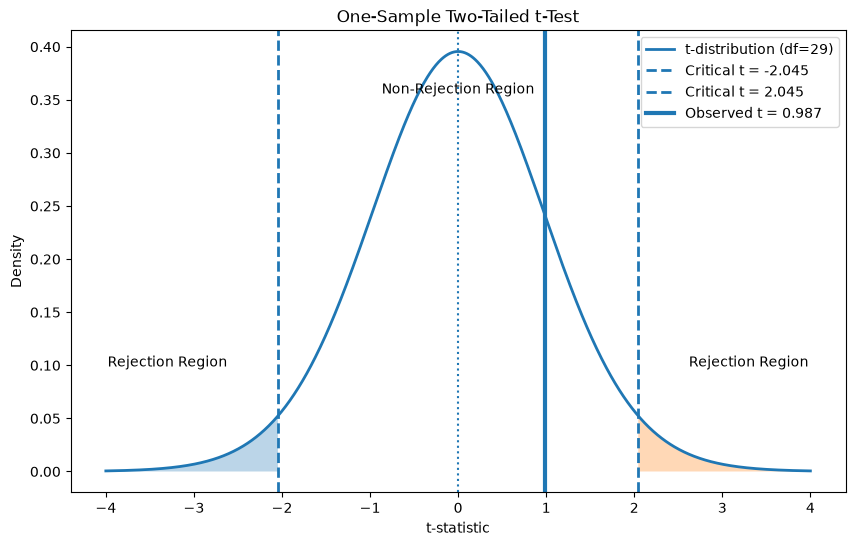

In [14]:
x = np.linspace(-4, 4, 1000)
y = stats.t.pdf(x, df=df_t)

plt.figure(figsize=(10, 6))

# t-distribution
plt.plot(x, y, linewidth=2, label=f"t-distribution (df={df_t})")

# Rejection regions
left_region = x <= -t_critical
right_region = x >= t_critical

plt.fill_between(
    x[left_region],
    y[left_region],
    alpha=0.3
)

plt.fill_between(
    x[right_region],
    y[right_region],
    alpha=0.3
)

# Critical values
plt.axvline(
    -t_critical,
    linestyle="--",
    linewidth=2,
    label=f"Critical t = {-t_critical:.3f}"
)

plt.axvline(
    t_critical,
    linestyle="--",
    linewidth=2,
    label=f"Critical t = {t_critical:.3f}"
)

# Observed t-statistic
plt.axvline(
    t_stat,
    linestyle="-",
    linewidth=3,
    label=f"Observed t = {t_stat:.3f}"
)

# Center
plt.axvline(
    0,
    linestyle=":",
    linewidth=1.5
)

plt.text(
    -3.3,
    max(y) * 0.25,
    "Rejection Region",
    ha="center"
)

plt.text(
    3.3,
    max(y) * 0.25,
    "Rejection Region",
    ha="center"
)

plt.text(
    0,
    max(y) * 0.9,
    "Non-Rejection Region",
    ha="center"
)

plt.xlabel("t-statistic")
plt.ylabel("Density")
plt.title("One-Sample Two-Tailed t-Test")
plt.legend()
plt.show()

In [15]:
print(f"Sample mean      : ₹{sample_mean_t:.2f}")
print(f"Sample SD        : ₹{sample_std_t:.2f}")
print(f"Sample size      : {sample_n_t}")
print(f"Degrees of freedom: {df_t}")
print(f"t-statistic      : {t_stat:.3f}")
print(f"Critical t       : ±{t_critical:.3f}")
print(f"p-value          : {p_value_t:.4f}")
print(f"Decision         : {decision_t}")

Sample mean      : ₹1836.97
Sample SD        : ₹1037.21
Sample size      : 30
Degrees of freedom: 29
t-statistic      : 0.987
Critical t       : ±2.045
p-value          : 0.3317
Decision         : Fail to reject H₀
